# Variational (Hardware-Efficient / Heuristic) Ansatz — Qiskit

**Primitive:** Heuristic Ansatz (a.k.a. Hardware-Efficient Ansatz), the kind of
parameterized circuit used as the trial state in VQE / QAOA-style variational algorithms.
It has no fixed physical meaning like Grover or QFT — it is a *template* built from
single-qubit rotation layers interleaved with fixed entangling layers, with the rotation
angles as free parameters. Here we fix the parameters to concrete numbers so the circuit
is deterministic and the Qiskit and CUDA-Q notebooks can be diffed directly.

## SETUP (identical in both notebooks — do not diverge)
- **N_QUBITS** = 2
- **Structure**: 3 rotation blocks (R0, R1, R2) interleaved with 2 entangling blocks (E0, E1)
  - R0: `RY(θ0) RZ(θ1)` on q0, `RY(θ2) RZ(θ3)` on q1
  - E0: `CNOT(control=q0, target=q1)`
  - R1: `RY(θ4) RZ(θ5)` on q0, `RY(θ6) RZ(θ7)` on q1
  - E1: `CNOT(control=q0, target=q1)`
  - R2 (final, no entangler after): `RY(θ8) RZ(θ9)` on q0, `RY(θ10) RZ(θ11)` on q1
- **θ (fixed, radians)** = `[0.30, 0.70, 1.10, 0.40, 0.90, 1.30, 0.50, 0.20, 1.05, 0.85, 0.35, 0.65]`
- **QUBIT ORDERING CONTRACT**: qubit 0 = rightmost bit in every printed bitstring
  (Qiskit's native convention — no reversal needed in this notebook).
- **SHOTS** = 10000, **SEED** = 42
- **GLOBAL PHASE CONVENTION**: normalize so the first amplitude with `abs(amp) > 1e-9`,
  in ascending bitstring order (`'00'`, `'01'`, `'10'`, `'11'`), is rotated to be real
  and positive: `phase = angle(amp)`, then multiply the whole vector by `exp(-1j*phase)`.
- **Basis ordering for matrices**: `{|00>, |01>, |10>, |11>}`, ascending binary order,
  i.e. row/column `i` corresponds to the computational basis state whose binary
  representation of `i` is `q1 q0` (q1 = MSB, q0 = LSB) — Qiskit's native tensor order.

## Theory recap
Each rotation gate is:

`RY(θ) = [[cos(θ/2), -sin(θ/2)], [sin(θ/2), cos(θ/2)]]`

`RZ(θ) = [[e^(-iθ/2), 0], [0, e^(iθ/2)]]`

A rotation block applies `RZ(θ_b) · RY(θ_a)` independently to each qubit (single-qubit
gates on different qubits commute as circuit operations — only their *order on the same
qubit* matters, and here RY is applied before RZ on every qubit, every block).
The entangler is a `CNOT` with qubit 0 as control and qubit 1 as target, expressed as a
fixed permutation matrix in the `{|00>,|01>,|10>,|11>}` basis:

```
CNOT(0->1) = [[1,0,0,0],
              [0,0,0,1],
              [0,0,1,0],
              [0,1,0,0]]
```
(it swaps the amplitudes of `|01>` and `|11>`, i.e. flips q1 whenever q0=1).

**Ordering-convention warning**: this notebook needs no bitstring reversal — Qiskit
already indexes statevector amplitudes and measurement counts with qubit 0 as the
rightmost/LSB bit. The matched CUDA-Q notebook must explicitly reverse every bitstring
(see its own ordering-fix cell) before its results are compared to this one.

**Run all cells top to bottom.**


In [1]:
# Install cell — exact package names for the current stable Qiskit release
# qiskit        : core circuit-building + quantum_info (Statevector, Operator)
# qiskit-aer    : AerSimulator backend used for shot-based sampling
# pylatexenc    : required by circuit.draw(output="mpl") for LaTeX-style gate labels
# matplotlib    : circuit drawing + histogram plotting
# Platform note: pure-Python wheels are published for Linux/macOS/Windows on CPython 3.9-3.12;
# no GPU/CUDA requirement for this small (2-qubit) circuit.
!pip install -q qiskit qiskit-aer pylatexenc matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 42.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 51.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 37.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 2.0 MB/s eta 0:00:00


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator

# ---- constants (must match the CUDA-Q notebook exactly) ----
N_QUBITS = 2
SHOTS = 10000
SEED = 42
THETA = np.array([0.30, 0.70, 1.10, 0.40, 0.90, 1.30, 0.50, 0.20, 1.05, 0.85, 0.35, 0.65])

print("N_QUBITS:", N_QUBITS)
print("SHOTS   :", SHOTS)
print("SEED    :", SEED)
print("THETA   :", THETA.tolist())

N_QUBITS: 2
SHOTS   : 10000
SEED    : 42
THETA   : [0.3, 0.7, 1.1, 0.4, 0.9, 1.3, 0.5, 0.2, 1.05, 0.85, 0.35, 0.65]


In [3]:
# Build the heuristic (hardware-efficient) ansatz, gate-by-gate.
# No measurements yet -- this circuit is used first to extract the exact statevector/operator.
qc = QuantumCircuit(N_QUBITS, name="heuristic_ansatz")

# --- Rotation block R0 ---
qc.ry(THETA[0], 0)   # single-qubit rotation about Y on q0: sets q0's population split
qc.rz(THETA[1], 0)   # single-qubit rotation about Z on q0: adds a relative phase on q0
qc.ry(THETA[2], 1)   # single-qubit rotation about Y on q1: sets q1's population split
qc.rz(THETA[3], 1)   # single-qubit rotation about Z on q1: adds a relative phase on q1

# --- Entangling block E0 ---
qc.cx(0, 1)          # CNOT: q0 is control, q1 is target -- creates entanglement between q0,q1

# --- Rotation block R1 ---
qc.ry(THETA[4], 0)
qc.rz(THETA[5], 0)
qc.ry(THETA[6], 1)
qc.rz(THETA[7], 1)

# --- Entangling block E1 ---
qc.cx(0, 1)

# --- Rotation block R2 (final layer, no entangler after it) ---
qc.ry(THETA[8], 0)
qc.rz(THETA[9], 0)
qc.ry(THETA[10], 1)
qc.rz(THETA[11], 1)

print(qc)

     ┌─────────┐┌─────────┐     ┌─────────┐┌─────────┐     ┌──────────┐»
q_0: ┤ Ry(0.3) ├┤ Rz(0.7) ├──■──┤ Ry(0.9) ├┤ Rz(1.3) ├──■──┤ Ry(1.05) ├»
     ├─────────┤├─────────┤┌─┴─┐├─────────┤├─────────┤┌─┴─┐├──────────┤»
q_1: ┤ Ry(1.1) ├┤ Rz(0.4) ├┤ X ├┤ Ry(0.5) ├┤ Rz(0.2) ├┤ X ├┤ Ry(0.35) ├»
     └─────────┘└─────────┘└───┘└─────────┘└─────────┘└───┘└──────────┘»
«     ┌──────────┐
«q_0: ┤ Rz(0.85) ├
«     ├──────────┤
«q_1: ┤ Rz(0.65) ├
«     └──────────┘


/usr/local/lib/python3.12/dist-packages/qiskit/visualization/circuit/matplotlib.py:273: UserWarning: Style JSON file 'default.json' not found in any of these locations: /usr/local/lib/python3.12/dist-packages/qiskit/visualization/circuit/styles/default.json, default.json. Will use default style.
  self._style, def_font_ratio = load_style(


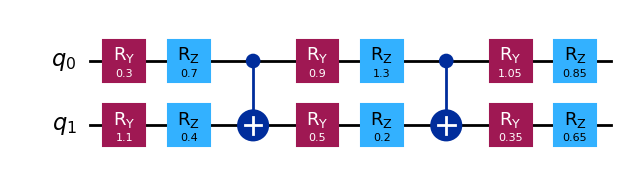

In [4]:
# Draw the circuit with matplotlib and save to disk.
fig = qc.draw(output="mpl", style={"name": "default"})
fig.savefig("heuristic_ansatz_qiskit_circuit.png", dpi=150, bbox_inches="tight")
fig

In [5]:
# Explicit matrix representation, built two ways and cross-checked.

def RY(t):
    c, s = np.cos(t/2), np.sin(t/2)
    return np.array([[c, -s], [s, c]], dtype=complex)

def RZ(t):
    return np.array([[np.exp(-1j*t/2), 0], [0, np.exp(1j*t/2)]], dtype=complex)

CNOT_01 = np.array([   # control=q0, target=q1, basis {|00>,|01>,|10>,|11>} = q1 q0 order
    [1, 0, 0, 0],
    [0, 0, 0, 1],
    [0, 0, 1, 0],
    [0, 1, 0, 0]
], dtype=complex)

def rot_block_matrix(t_q0_ry, t_q0_rz, t_q1_ry, t_q1_rz):
    U_q0 = RZ(t_q0_rz) @ RY(t_q0_ry)
    U_q1 = RZ(t_q1_rz) @ RY(t_q1_ry)
    return np.kron(U_q1, U_q0)   # q1 (MSB) kron q0 (LSB) -- Qiskit's native tensor order

# (a) hand-built, gate-by-gate, in NumPy
U_R0 = rot_block_matrix(THETA[0], THETA[1], THETA[2], THETA[3])
U_R1 = rot_block_matrix(THETA[4], THETA[5], THETA[6], THETA[7])
U_R2 = rot_block_matrix(THETA[8], THETA[9], THETA[10], THETA[11])
U_handbuilt = U_R2 @ CNOT_01 @ U_R1 @ CNOT_01 @ U_R0

print("Hand-built full unitary U (NumPy), basis {|00>,|01>,|10>,|11>}, rounded to 4 dp:")
print(np.round(U_handbuilt, 4))

# (b) from Qiskit's own operator extraction
U_qiskit_op = Operator(qc).data

print("\nQiskit Operator(qc), rounded to 4 dp:")
print(np.round(U_qiskit_op, 4))

max_diff = np.max(np.abs(U_handbuilt - U_qiskit_op))
print(f"\nMax |hand-built - qiskit-operator| element difference: {max_diff:.2e}")
assert max_diff < 1e-9, "Hand-built matrix and Qiskit Operator disagree!"
print("Matrices match.")

Hand-built full unitary U (NumPy), basis {|00>,|01>,|10>,|11>}, rounded to 4 dp:
[[-0.4759-0.351j  -0.3881+0.0033j  0.0036+0.6696j  0.0214+0.2255j]
 [ 0.2684-0.0356j  0.2838+0.5798j -0.0286+0.4556j -0.4472-0.3187j]
 [ 0.098 -0.5096j -0.4503+0.0365j  0.4724-0.3374j -0.2689-0.3424j]
 [ 0.5207+0.1911j -0.4215+0.2255j  0.079 +0.0067j -0.1465+0.6604j]]

Qiskit Operator(qc), rounded to 4 dp:
[[-0.4759-0.351j  -0.3881+0.0033j  0.0036+0.6696j  0.0214+0.2255j]
 [ 0.2684-0.0356j  0.2838+0.5798j -0.0286+0.4556j -0.4472-0.3187j]
 [ 0.098 -0.5096j -0.4503+0.0365j  0.4724-0.3374j -0.2689-0.3424j]
 [ 0.5207+0.1911j -0.4215+0.2255j  0.079 +0.0067j -0.1465+0.6604j]]

Max |hand-built - qiskit-operator| element difference: 3.51e-16
Matrices match.


In [6]:
# Exact statevector, with global-phase normalization (no bit-order fix needed for Qiskit).

def normalize_global_phase(vec, labels_ascending):
    vec = vec.copy()
    for amp in vec:
        if abs(amp) > 1e-9:
            phase = np.angle(amp)
            return vec * np.exp(-1j*phase)
    return vec

sv = Statevector(qc)
labels = [format(i, f"0{N_QUBITS}b") for i in range(2**N_QUBITS)]  # ascending: '00','01','10','11'
amps = sv.data
amps_normalized = normalize_global_phase(amps, labels)

print("Amplitudes (phase-normalized):")
for lab, amp in zip(labels, amps_normalized):
    print(f"  |{lab}>: {amp:.6f}")

probs_statevector = {lab: float(abs(amp)**2) for lab, amp in zip(labels, amps_normalized)}
probs_statevector = dict(sorted(probs_statevector.items()))
print("\nProbability dictionary (sorted by bitstring):")
print(probs_statevector)

Amplitudes (phase-normalized):
  |00>: 0.591331-0.000000j
  |01>: -0.194904+0.187977j
  |10>: 0.223655+0.468285j
  |11>: -0.532517+0.155299j

Probability dictionary (sorted by bitstring):
{'00': 0.3496723715344666, '01': 0.07332289770218928, '10': 0.2693125334621995, '11': 0.30769219730114455}


**Ordering-fix note:** no reversal was applied in this notebook. Qiskit's
`Statevector`/`AerSimulator` already index amplitudes and counts with qubit 0 as the
rightmost (least-significant) bit of every printed bitstring, which is the ordering
contract fixed in the SETUP block above. The CUDA-Q notebook must reverse its raw
bitstrings to match this convention before its `CUDAQ_RESULT` can be diffed against
`QISKIT_RESULT` below.

In [7]:
# Measurement / sampling cell.
qc_meas = qc.copy()
qc_meas.measure_all()

sim = AerSimulator(seed_simulator=SEED)
qc_meas_t = transpile(qc_meas, sim)
result = sim.run(qc_meas_t, shots=SHOTS, seed_simulator=SEED).result()
counts = result.get_counts()

# Qiskit already reports counts with qubit 0 as the rightmost bit -- no reordering needed.
probs_sampled = {lab: counts.get(lab, 0) / SHOTS for lab in labels}
probs_sampled = dict(sorted(probs_sampled.items()))
print("Sampled probability dictionary (sorted by bitstring):")
print(probs_sampled)

Sampled probability dictionary (sorted by bitstring):
{'00': 0.3441, '01': 0.072, '10': 0.275, '11': 0.3089}


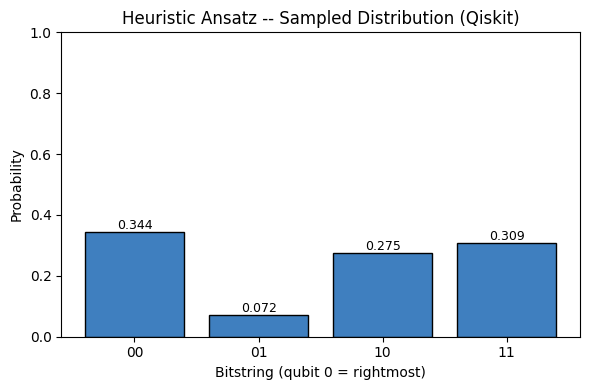

In [8]:
# Histogram cell -- matplotlib bar chart, same axis ranges/labels/style as the CUDA-Q notebook.
fig2, ax2 = plt.subplots(figsize=(6, 4))
sorted_labels = sorted(probs_sampled.keys())
values = [probs_sampled[l] for l in sorted_labels]
ax2.bar(sorted_labels, values, color="#3f7fbf", edgecolor="black")
ax2.set_xlabel("Bitstring (qubit 0 = rightmost)")
ax2.set_ylabel("Probability")
ax2.set_ylim(0, 1)
ax2.set_title("Heuristic Ansatz -- Sampled Distribution (Qiskit)")
for i, v in enumerate(values):
    ax2.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("heuristic_ansatz_qiskit_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# Resource counts.
depth = qc.depth()
op_counts = qc.count_ops()
print("Circuit depth:", depth)
print("Gate counts  :", dict(op_counts))

Circuit depth: 8
Gate counts  : {'ry': 6, 'rz': 6, 'cx': 2}


**Convention notes (plain text):**
- Bit ordering: qubit 0 = rightmost bit in every bitstring above; this is Qiskit's native
  convention, so **no reversal was applied** in this notebook.
- Global phase: the statevector was rotated so that the first basis state (in ascending
  bitstring order `'00' < '01' < '10' < '11'`) with nonzero amplitude has a real, positive
  coefficient, before probabilities were computed.

In [10]:
# Final result dictionary.
QISKIT_RESULT = probs_sampled
print("QISKIT_RESULT =", QISKIT_RESULT)

QISKIT_RESULT = {'00': 0.3441, '01': 0.072, '10': 0.275, '11': 0.3089}


In [11]:
# Diff-check block (run this after also running the CUDA-Q notebook and pasting its
# CUDAQ_RESULT dict below, or import it however you like -- left commented out since
# this notebook can't see the other kernel's variables).
#
# CUDAQ_RESULT = {...}  # paste from the CUDA-Q notebook's final cell
#
# hand_computed_expected = {
#     '00': 0.349672, '01': 0.073323, '10': 0.269313, '11': 0.307692
# }  # from re-deriving the statevector by hand (see prompt notes) -- shot noise means
#    # QISKIT_RESULT/CUDAQ_RESULT will be close but not exact to these; the *exact*
#    # (non-sampled) probs_statevector dict computed above should match to ~1e-9.
#
# max_delta = max(abs(QISKIT_RESULT[k] - CUDAQ_RESULT[k]) for k in QISKIT_RESULT)
# print("Max prob delta:", max_delta)
# assert max_delta < 1e-3, "Qiskit and CUDA-Q results disagree beyond tolerance!"